In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix

In [2]:
raw_train = (pd.read_csv('data/mnist_train.csv', header=None)
         .rename(columns={0: 'label'}))
raw_test = (pd.read_csv('data/mnist_test.csv', header=None)
        .rename(columns={0: 'label'}))

In [3]:
def filter_df(df, label_map, N):
    nums_df = [(df.query(f'label == {num}').iloc[:N] / 255)
               .assign(label=[label] * N) 
               for label, num in label_map.items()]
    return pd.concat(nums_df).reset_index(drop=True)

label_map = {1: 1, -1: 2}
train_df = filter_df(raw_train, label_map, 2000)
test_df = filter_df(raw_test, label_map, 500)

In [4]:
X = train_df.iloc[:, 1:].to_numpy()
Y = train_df.iloc[:, 0].to_numpy()
w0 = np.zeros(X.shape[1])

f = lambda w, x, y: np.log(1 + np.exp(-y * np.dot(x, w)))
F = lambda w: np.mean([f(w, x, y) for x, y in zip(X, Y)])
grad_f = lambda w, x, y: (-y * x) / (1 + np.exp(y * np.dot(x, w)))
grad_F = lambda w: np.mean([grad_f(w, x, y) for x, y in zip(X, Y)], axis=0)

In [5]:
def train(w, descend, step_fn, title, T=2_000):
    losses = np.array([np.log(F(w))])
    for t in tqdm(np.arange(T)):
        w = descend(w, step_fn(t))
        losses = np.append(losses, np.log(F(w)))
        
    plt.plot(losses)
    plt.xlabel('Iterations')
    plt.ylabel('Loss')
    plt.title(title)
    plt.show()
    
    return w

  0%|          | 0/2000 [00:00<?, ?it/s]

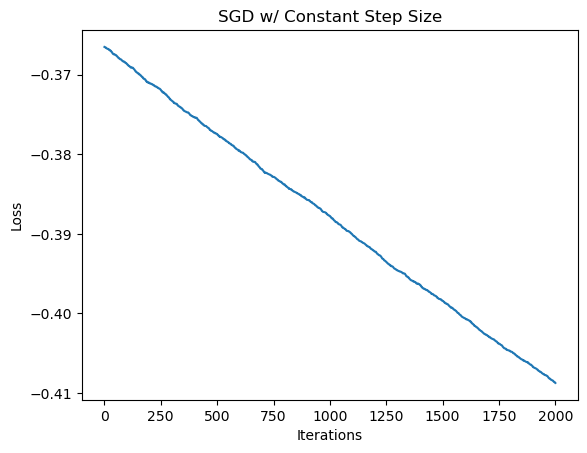

In [11]:
# Question 1a
const_step = lambda _: 1e-5

def SGD(w, step):
    sample = train_df.sample(n=1)
    x = sample.iloc[0, 1:]
    y = sample.iloc[0, 0]
    return w - step * grad_f(w, x, y)

w1 = train(w0, SGD, const_step, title='SGD w/ Constant Step Size')

  0%|          | 0/50 [00:00<?, ?it/s]

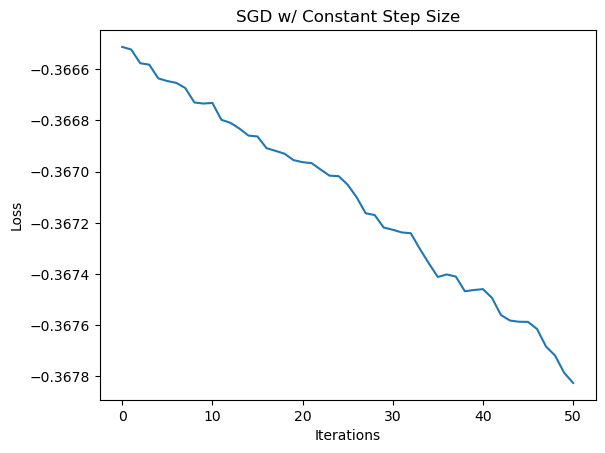

  0%|          | 0/2000 [00:00<?, ?it/s]

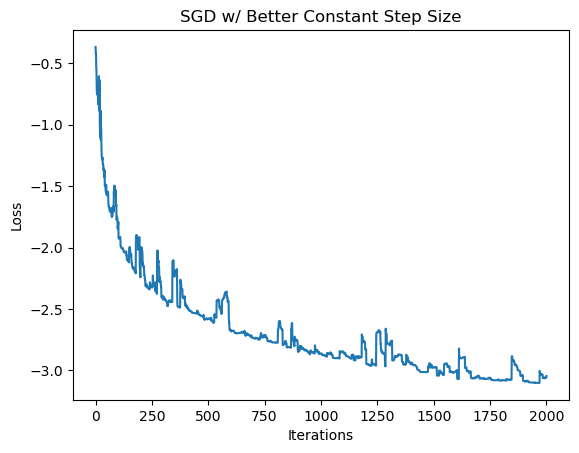

In [50]:
# Question 1b
_ = train(w0, SGD, const_step, title='SGD w/ Constant Step Size', T=50)
_ = train(w0, SGD, lambda _: 3e-2, title='SGD w/ Better Constant Step Size')

In [32]:
def display_confusion_matrix(w, df, df_type, ax):
    X = df.iloc[:, 1:].to_numpy()
    Y = df.iloc[:, 0].to_numpy()
    predictions = np.sign(np.dot(X, w))
    
    cm = confusion_matrix(Y, predictions, labels=[1, -1])
    cm_percentages = cm / cm.sum(axis=1, keepdims=True) * 100
    accuracy = (Y == predictions).mean() * 100

    ax.imshow(cm, cmap='Blues')
    ax.set_title(f'{df_type} Confusion Matrix - Accuracy: {accuracy:.1f}%')

    for i, j in np.ndindex(cm.shape):
        ax.text(j, i, f'{cm[i, j]}\n({cm_percentages[i, j]:.1f}%)', 
            ha='center', va='center', 
            color='white' if cm_percentages[i, j] > 50 else 'black')

    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_xticks([0, 1], [1, -1])
    ax.set_yticks([0, 1], [1, -1])
    
def display_cm(w):
    _, ax = plt.subplots(1, 2, figsize=(10, 5))
    display_confusion_matrix(w, test_df, 'Test', ax[0])
    display_confusion_matrix(w, train_df, 'Train', ax[1])
    plt.show()

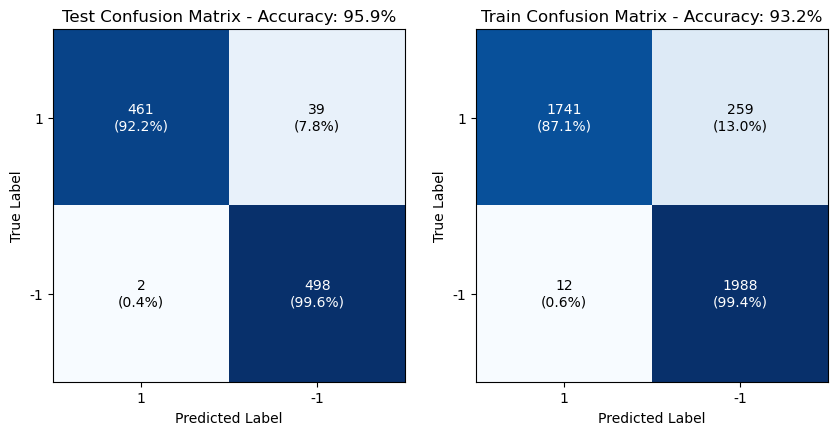

In [33]:
# Question 1c
display_cm(w1)

  0%|          | 0/2000 [00:00<?, ?it/s]

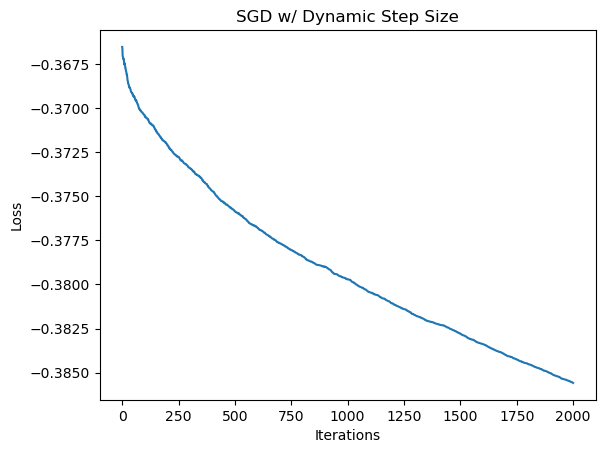

In [54]:
# Question 2a
dynamic_step = lambda t: 1e-4 * np.sqrt(1 / (t + 1))
w2 = train(w0, SGD, dynamic_step, title='SGD w/ Dynamic Step Size', T=2_000)

  0%|          | 0/2000 [00:00<?, ?it/s]

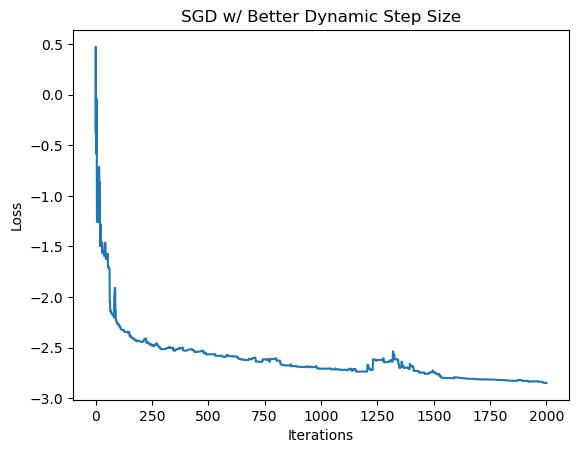

In [53]:
# Question 2b
better_dynamic_step = lambda t: 0.3 * np.sqrt(1 / (t + 1))
_ = train(w0, SGD, dynamic_step, title='SGD w/ Dynamic Step Size', T=50)
_ = train(w0, SGD, better_dynamic_step, title='SGD w/ Better Dynamic Step Size')

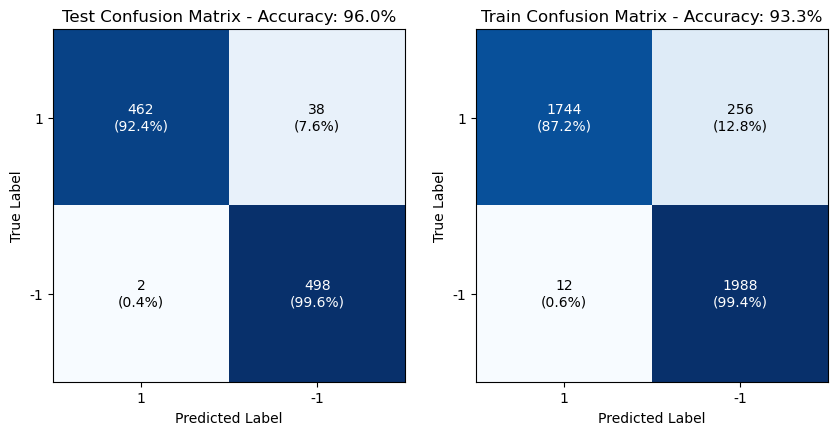

In [55]:
# Question 2c
display_cm(w2)

  0%|          | 0/2000 [00:00<?, ?it/s]

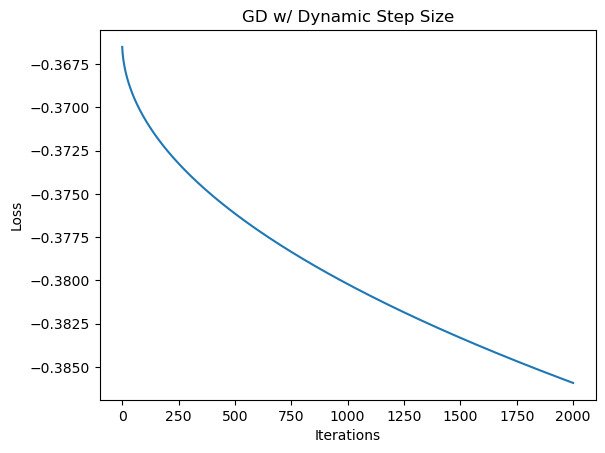

In [57]:
# Question 3a
GD = lambda w, step: w - step * grad_F(w)
w3 = train(w0, GD, dynamic_step, title='GD w/ Dynamic Step Size')

  0%|          | 0/2000 [00:00<?, ?it/s]

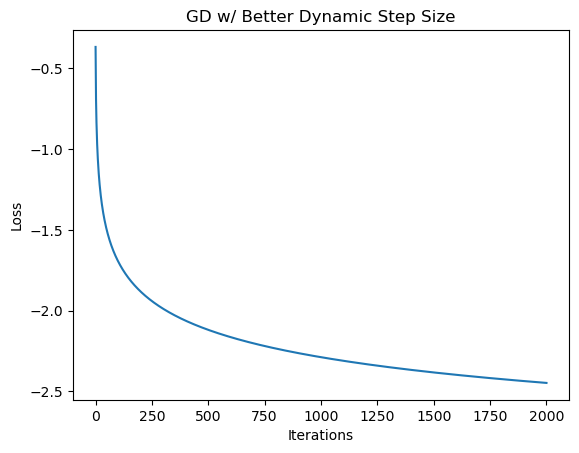

In [47]:
# Question 3b
_ = train(w0, GD, better_dynamic_step, title='GD w/ Better Dynamic Step Size')

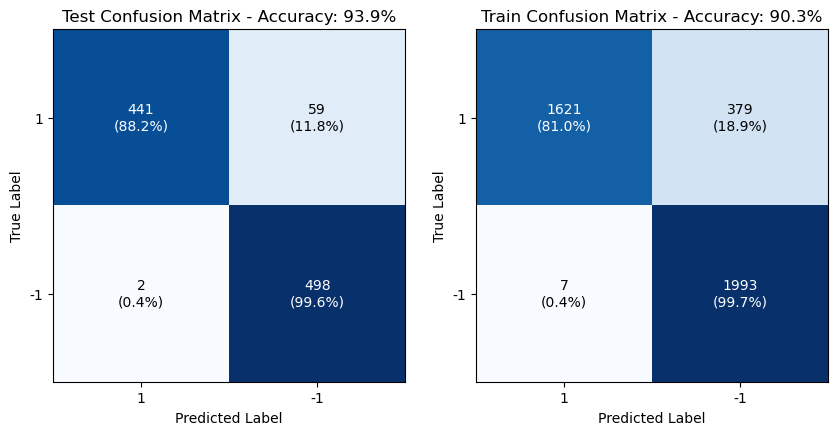

In [58]:
# Question 3c
display_cm(w3)